# CustOmics on GS-BRCA: PAM50 subtype classification

**Goal:** classify 671 TCGA breast-cancer patients into the 5 PAM50 subtypes from 4 omics layers
(mRNA, DNA methylation, CNV, miRNA), using the best architecture found in `reference_material/`.

**Data:** MLOmics `GS-BRCA/Original`, the same *Original* feature scale used by the pan-cancer reference notebooks
(`custOmics2.ipynb`): the full gene sets, z-scored, with no missing values (18 206 mRNA, 19 049 methylation,
19 568 CNV and 368 miRNA features).

**What the reference material established**

| Source | Model | Data | Accuracy | Macro-F1 |
|---|---|---|---|---|
| `customics_pancancer1.ipynb` | 3 omics, central VAE (64-D) | Pan-cancer, 5-fold | 0.9667 | 0.9427 |
| `custOmics2.ipynb` | **4 omics, direct fusion (4 × 64 = 256-D)** | Pan-cancer, 5-fold | **0.9725** | **0.9640** |
| `CustOmics_BRCA.pdf` | 4 omics, central VAE (32-D) | GS-BRCA **Top** features, one 60/20/20 split | 0.837 | 0.789 |

The direct-fusion model is the strongest so far, but it has never been run on BRCA with cross-validation.
BRCA is also a very different regime: only 671 patients but about 57 000 input features, so the pan-cancer
settings overfit within a few epochs. This notebook therefore runs a small **controlled comparison under one
5-fold protocol**:

* the reference settings vs. a **regularised** version (dropout 0.5, weight decay 1e-3, 128 hidden units,
  20 phase-1 epochs);
* with and without miRNA (the synopsis asks whether miRNA helps or adds noise);
* direct fusion vs. the central VAE (whether the central-integration stage helps).

The best model is chosen by macro-F1 (the fair metric under class imbalance) and saved to `results/brca/`.

In [1]:
import os, copy, json, random, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report, confusion_matrix,
                             f1_score, normalized_mutual_info_score, precision_score, recall_score,
                             roc_auc_score, silhouette_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
N_FOLDS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "data/MLOmics/Main_Dataset/Classification_datasets/GS-BRCA/Original"
RESULTS_DIR = "results/brca"
os.makedirs(RESULTS_DIR, exist_ok=True)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cuda NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Load data

In [2]:
OMICS = ["mRNA", "Methy", "CNV", "miRNA"]

X_all = {}
for m in OMICS:
    df = pd.read_csv(os.path.join(DATA_DIR, f"BRCA_{m}.csv"), index_col=0).T      # -> patients x features
    X_all[m] = df.dropna(axis=1, how="all")                                        # drop features never measured
y = pd.read_csv(os.path.join(DATA_DIR, "BRCA_label_num.csv"))["Label"].to_numpy()

patients = X_all["mRNA"].index
assert all(X_all[m].index.equals(patients) for m in OMICS) and len(y) == len(patients)
N_CLASSES = len(np.unique(y))

print(f"{len(patients)} patients, {N_CLASSES} PAM50 subtypes\n")
print(pd.DataFrame({m: [X_all[m].shape[1], int(X_all[m].isna().sum().sum())] for m in OMICS},
                   index=["features", "missing values"]))
print("\nPatients per class:", pd.Series(y).value_counts().sort_index().to_dict())

671 patients, 5 PAM50 subtypes

                 mRNA  Methy    CNV  miRNA
features        18206  19049  19568    368
missing values      0      0      0      0

Patients per class: {0: 353, 1: 42, 2: 132, 3: 31, 4: 113}


## 2. Model: CustOmics mixed integration

* **Phase 1 – per-omics autoencoders.** Each omics source has its own encoder/decoder
  (`Linear → BatchNorm → ReLU → Dropout → Linear → BatchNorm → ReLU`) that compresses it to a 64-D sub-latent.
  As in the CustOmics paper, each source also gets a small auxiliary classifier head in this phase, so the sub-latent
  is pushed to hold subtype signal, not only reconstructable variance.
* **Phase 2 – fusion + classification.** The sub-latents are fused and fed to the classifier; everything is fine-tuned
  end-to-end with `reconstruction + 2 × cross-entropy`.
  * `fusion="direct"`: concatenate the sub-latents (4 × 64 = 256-D) → classifier. This was the **best model in
    `reference_material`** (`custOmics2.ipynb`, pan-cancer acc 0.9725 / macro-F1 0.9640).
  * `fusion="vae"`: concatenate → central VAE with MMD regularisation → classifier on μ (the original CustOmics design,
    `customics_pancancer1.ipynb`, acc 0.9667 / macro-F1 0.9427).
* Cross-entropy is **class-weighted** (inverse class frequency), the imbalance fix proposed in the synopsis.

In [3]:
class SourceAE(nn.Module):
    """Per-omics autoencoder: compresses one omics source to a small latent vector."""
    def __init__(self, in_dim, latent_dim, hidden=256, dropout=0.2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, latent_dim), nn.BatchNorm1d(latent_dim), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(),
            nn.Linear(hidden, in_dim))


class CustOmics(nn.Module):
    """Per-omics autoencoders -> fusion ("direct" concat or central "vae") -> classifier."""
    def __init__(self, in_dims, n_classes, latent_dim=64, fusion="direct", central_dim=64, hidden=256, dropout=0.2):
        super().__init__()
        self.omics, self.fusion = list(in_dims), fusion
        self.aes = nn.ModuleDict({m: SourceAE(d, latent_dim, hidden, dropout) for m, d in in_dims.items()})
        self.aux_heads = nn.ModuleDict({m: nn.Linear(latent_dim, n_classes) for m in in_dims})  # phase 1 only
        fused_dim = latent_dim * len(in_dims)
        if fusion == "vae":
            self.central_enc = nn.Sequential(nn.Linear(fused_dim, 128), nn.BatchNorm1d(128), nn.ReLU())
            self.fc_mu, self.fc_logvar = nn.Linear(128, central_dim), nn.Linear(128, central_dim)
            self.central_dec = nn.Sequential(nn.Linear(central_dim, 128), nn.BatchNorm1d(128), nn.ReLU(),
                                             nn.Linear(128, fused_dim))
            fused_dim = central_dim
        self.classifier = nn.Sequential(nn.Linear(fused_dim, 128), nn.BatchNorm1d(128), nn.ReLU(),
                                        nn.Dropout(dropout), nn.Linear(128, n_classes))

    def encode(self, xs):
        return {m: self.aes[m].encoder(xs[m]) for m in self.omics}

    def forward(self, xs):
        z = self.encode(xs)
        out = {"recon": {m: self.aes[m].decoder(z[m]) for m in self.omics}}
        h = torch.cat([z[m] for m in self.omics], dim=1)
        if self.fusion == "vae":
            e = self.central_enc(h)
            mu, logvar = self.fc_mu(e), self.fc_logvar(e)
            zc = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
            out.update(h=h, h_hat=self.central_dec(zc), zc=zc)
            h = mu
        out["latent"], out["logits"] = h, self.classifier(h)
        return out


def mmd(z):
    """MMD between z and samples of N(0, I), RBF kernel with bandwidth = latent dim."""
    prior = torch.randn_like(z)
    k = lambda a, b: torch.exp(-torch.cdist(a, b).pow(2) / z.shape[1])
    return k(z, z).mean() + k(prior, prior).mean() - 2 * k(z, prior).mean()

## 3. Training and evaluation

* **Stratified 5-fold CV.** Inside every training fold, 15 % is held out (stratified) as a validation set used only
  for early stopping. The test fold is never touched during training or model selection.
* **Preprocessing** (median imputation + standardisation per omics) is fitted on the training patients of each fold only.
* The best epoch is chosen by the lowest validation cross-entropy, and a real copy of its weights is restored
  (`copy.deepcopy`). The reference notebooks used `state_dict().copy()`, which is a shallow copy and silently
  keeps the *last* weights.
* Metrics on each test fold: accuracy, macro precision / recall / F1, ROC-AUC (one-vs-rest), NMI and ARI.

In [4]:
CFG = dict(omics=OMICS, latent_dim=64, fusion="direct", hidden=256, dropout=0.2, lr=1e-3, weight_decay=1e-4,
           batch_size=64, p1_epochs=50, p2_epochs=150, min_epochs=30, patience=20, ce_weight=2.0, mmd_weight=1.0)
METRICS = ["accuracy", "precision", "recall", "f1_macro", "roc_auc", "nmi", "ari"]
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))


def fit_preprocessors(idx, omics):
    """Median-impute + standardise each omics source, fitted on the given (training) patients only."""
    return {m: make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_all[m].iloc[idx])
            for m in omics}


def to_tensors(idx, pipes):
    return {m: torch.tensor(p.transform(X_all[m].iloc[idx]), dtype=torch.float32, device=DEVICE)
            for m, p in pipes.items()}


def minibatches(n, batch_size):
    idx = torch.randperm(n, device=DEVICE)
    return [b for b in idx.split(batch_size) if len(b) > 1]  # BatchNorm needs > 1 sample


@torch.no_grad()
def predict(model, xs, batch_size=1024):
    model.eval()
    n = len(next(iter(xs.values())))
    probs, latents = [], []
    for s in range(0, n, batch_size):
        out = model({m: x[s:s + batch_size] for m, x in xs.items()})
        probs.append(F.softmax(out["logits"], dim=1).cpu())
        latents.append(out["latent"].cpu())
    return torch.cat(probs).numpy(), torch.cat(latents).numpy()


def train_model(xs_tr, y_tr, xs_va, y_va, cfg, class_weights):
    omics = cfg["omics"]
    model = CustOmics({m: xs_tr[m].shape[1] for m in omics}, N_CLASSES, cfg["latent_dim"], cfg["fusion"],
                      hidden=cfg["hidden"], dropout=cfg["dropout"]).to(DEVICE)
    ce = nn.CrossEntropyLoss(weight=class_weights)
    n = len(y_tr)

    # Phase 1: each omics autoencoder learns to reconstruct its source and predict the label
    opt = torch.optim.Adam([*model.aes.parameters(), *model.aux_heads.parameters()],
                           lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    for _ in range(cfg["p1_epochs"]):
        model.train()
        for b in minibatches(n, cfg["batch_size"]):
            z = model.encode({m: xs_tr[m][b] for m in omics})
            loss = sum(F.mse_loss(model.aes[m].decoder(z[m]), xs_tr[m][b]) + ce(model.aux_heads[m](z[m]), y_tr[b])
                       for m in omics)
            opt.zero_grad(); loss.backward(); opt.step()

    # Phase 2: fuse the sub-latents and fine-tune everything end-to-end
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    best = {"loss": float("inf"), "epoch": 0, "state": None}
    for epoch in range(1, cfg["p2_epochs"] + 1):
        model.train()
        for b in minibatches(n, cfg["batch_size"]):
            xb = {m: xs_tr[m][b] for m in omics}
            out = model(xb)
            loss = sum(F.mse_loss(out["recon"][m], xb[m]) for m in omics) + cfg["ce_weight"] * ce(out["logits"], y_tr[b])
            if cfg["fusion"] == "vae":
                loss = loss + F.mse_loss(out["h_hat"], out["h"].detach()) + cfg["mmd_weight"] * mmd(out["zc"])
            opt.zero_grad(); loss.backward(); opt.step()

        # early stopping on the inner validation split
        model.eval()
        with torch.no_grad():
            val_loss = ce(model(xs_va)["logits"], y_va).item()
        if val_loss < best["loss"] - 1e-4:
            best = {"loss": val_loss, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        elif epoch >= cfg["min_epochs"] and epoch - best["epoch"] >= cfg["patience"]:
            break
    model.load_state_dict(best["state"])
    return model, best["epoch"]


def scores(y_true, proba):
    y_pred = proba.argmax(1)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro"),
            "roc_auc": roc_auc_score(y_true, proba, multi_class="ovr", labels=np.arange(N_CLASSES)),
            "nmi": normalized_mutual_info_score(y_true, y_pred),
            "ari": adjusted_rand_score(y_true, y_pred)}


def run_cv(name, cfg):
    """Stratified 5-fold CV; returns per-fold metrics, out-of-fold predictions/latents and the trained models."""
    rows, models, oof_proba, oof_latent = [], [], np.zeros((len(y), N_CLASSES)), None
    t0 = time.time()
    for fold, (train_idx, test_idx) in enumerate(FOLDS, 1):
        set_seed(SEED + fold)
        fit_idx, val_idx = train_test_split(train_idx, test_size=0.15, stratify=y[train_idx], random_state=SEED)
        pipes = fit_preprocessors(fit_idx, cfg["omics"])
        xs_fit, xs_val, xs_test = (to_tensors(i, pipes) for i in (fit_idx, val_idx, test_idx))
        y_fit, y_val = (torch.tensor(y[i], device=DEVICE) for i in (fit_idx, val_idx))
        counts = np.bincount(y[fit_idx], minlength=N_CLASSES)
        class_weights = torch.tensor(len(fit_idx) / (N_CLASSES * counts), dtype=torch.float32, device=DEVICE)

        model, best_epoch = train_model(xs_fit, y_fit, xs_val, y_val, cfg, class_weights)
        proba, latent = predict(model, xs_test)
        oof_proba[test_idx] = proba
        if oof_latent is None:
            oof_latent = np.zeros((len(y), latent.shape[1]), dtype=np.float32)
        oof_latent[test_idx] = latent
        rows.append({"fold": fold, **scores(y[test_idx], proba), "best_epoch": best_epoch})
        models.append({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "preprocess": pipes,
                       "in_dims": {m: xs_fit[m].shape[1] for m in cfg["omics"]}})
        print(f"[{name}] fold {fold}: acc={rows[-1]['accuracy']:.4f}  macro-F1={rows[-1]['f1_macro']:.4f}  "
              f"best epoch={best_epoch}")
    print(f"[{name}] finished in {time.time() - t0:.0f}s\n")
    return {"name": name, "cfg": cfg, "folds": pd.DataFrame(rows), "oof_proba": oof_proba,
            "oof_latent": oof_latent, "models": models}


def summary_table(runs):
    """mean ± std over the 5 test folds for every run."""
    return pd.DataFrame({r["name"]: {k: f"{r['folds'][k].mean():.4f} ± {r['folds'][k].std():.4f}" for k in METRICS}
                         for r in runs}).T


def save_run(run, out_dir, class_names=None):
    """Save fold models, preprocessing, metrics and out-of-fold predictions of one run."""
    os.makedirs(os.path.join(out_dir, "models"), exist_ok=True)
    for fold, m in enumerate(run["models"], 1):
        torch.save({"state_dict": m["state_dict"], "in_dims": m["in_dims"], "n_classes": N_CLASSES, "config": run["cfg"]},
                   os.path.join(out_dir, "models", f"fold_{fold}.pt"))
        joblib.dump(m["preprocess"], os.path.join(out_dir, "models", f"preprocess_fold_{fold}.joblib"))
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump({"name": run["name"], **run["cfg"], "seed": SEED, "n_folds": N_FOLDS}, f, indent=2)

    run["folds"].to_csv(os.path.join(out_dir, "cv_metrics_per_fold.csv"), index=False)
    summary = run["folds"][METRICS].agg(["mean", "std"]).T
    summary.to_csv(os.path.join(out_dir, "cv_metrics_summary.csv"))

    y_pred = run["oof_proba"].argmax(1)
    preds = pd.DataFrame(run["oof_proba"], index=patients, columns=[f"p_class_{c}" for c in range(N_CLASSES)])
    preds.insert(0, "y_pred", y_pred); preds.insert(0, "y_true", y)
    preds.to_csv(os.path.join(out_dir, "oof_predictions.csv"), index_label="patient")
    np.save(os.path.join(out_dir, "oof_latent.npy"), run["oof_latent"])

    report = pd.DataFrame(classification_report(y, y_pred, target_names=class_names, output_dict=True,
                                                zero_division=0)).T
    report.to_csv(os.path.join(out_dir, "per_class_metrics.csv"))
    return summary, report

## 4. Controlled comparison on BRCA

All runs use the same folds, preprocessing and training settings; only one factor changes at a time.
A class-weighted logistic regression on the concatenated features (early integration) is included as a classical baseline.

In [5]:
from sklearn.linear_model import LogisticRegression


def run_logreg_baseline(name="LogReg baseline (early integration)"):
    rows, oof = [], np.zeros((len(y), N_CLASSES))
    for fold, (train_idx, test_idx) in enumerate(FOLDS, 1):
        pipes = fit_preprocessors(train_idx, OMICS)
        X_tr = np.hstack([pipes[m].transform(X_all[m].iloc[train_idx]) for m in OMICS])
        X_te = np.hstack([pipes[m].transform(X_all[m].iloc[test_idx]) for m in OMICS])
        clf = LogisticRegression(max_iter=3000, class_weight="balanced").fit(X_tr, y[train_idx])
        oof[test_idx] = clf.predict_proba(X_te)
        rows.append({"fold": fold, **scores(y[test_idx], oof[test_idx])})
    print(f"[{name}] done\n")
    return {"name": name, "folds": pd.DataFrame(rows), "oof_proba": oof}


REG = dict(dropout=0.5, weight_decay=1e-3, hidden=128, p1_epochs=20)  # stronger regularisation for small cohorts

EXPERIMENTS = {
    "Direct fusion | 4 omics | reference settings":   dict(CFG),
    "Direct fusion | 4 omics | regularised":          dict(CFG, **REG),
    "Direct fusion | 3 omics (no miRNA) | regularised": dict(CFG, **REG, omics=["mRNA", "Methy", "CNV"]),
    "Central VAE   | 4 omics | regularised":          dict(CFG, **REG, fusion="vae"),
}

baseline = run_logreg_baseline()
runs = [run_cv(name, cfg) for name, cfg in EXPERIMENTS.items()]

[LogReg baseline (early integration)] done



[Direct fusion | 4 omics | reference settings] fold 1: acc=0.8222  macro-F1=0.7941  best epoch=28


[Direct fusion | 4 omics | reference settings] fold 2: acc=0.7463  macro-F1=0.6918  best epoch=13


[Direct fusion | 4 omics | reference settings] fold 3: acc=0.8209  macro-F1=0.7318  best epoch=67


[Direct fusion | 4 omics | reference settings] fold 4: acc=0.7463  macro-F1=0.6893  best epoch=21


...

[Central VAE   | 4 omics | regularised] fold 1: acc=0.8593  macro-F1=0.8481  best epoch=11


[Central VAE   | 4 omics | regularised] fold 2: acc=0.8134  macro-F1=0.7398  best epoch=10


[Central VAE   | 4 omics | regularised] fold 3: acc=0.8209  macro-F1=0.7264  best epoch=7


[Central VAE   | 4 omics | regularised] fold 4: acc=0.8806  macro-F1=0.8261  best epoch=13


[Central VAE   | 4 omics | regularised] fold 5: acc=0.7985  macro-F1=0.6986  best epoch=22
[Central VAE   | 4 omics | regularised] finished in 42s



,accuracy,precision,recall,f1_macro,roc_auc,nmi,ari
LogReg baseline (early integration),0.8390 ± 0.0336,0.7778 ± 0.0586,0.7618 ± 0.0574,0.7621 ± 0.0549,0.9596 ± 0.0139,0.6364 ± 0.0601,0.6510 ± 0.0677
Direct fusion | 4 omics | reference settings,0.7853 ± 0.0378,0.7247 ± 0.0368,0.7473 ± 0.0395,0.7221 ± 0.0437,0.9415 ± 0.0125,0.5632 ± 0.0386,0.5442 ± 0.0669
Direct fusion | 4 omics | regularised,0.8420 ± 0.0414,0.7879 ± 0.0630,0.8103 ± 0.0329,0.7918 ± 0.0471,0.9576 ± 0.0224,0.6481 ± 0.0388,0.6454 ± 0.0857
Direct fusion | 3 omics (no miRNA) | regularised,0.7988 ± 0.0357,0.7435 ± 0.0573,0.8034 ± 0.0464,0.7584 ± 0.0445,0.9493 ± 0.0222,0.5928 ± 0.0518,0.5597 ± 0.0674
Central VAE | 4 omics | regularised,0.8345 ± 0.0341,0.7857 ± 0.0698,0.7664 ± 0.0642,0.7678 ± 0.0654,0.9544 ± 0.0219,0.6200 ± 0.0666,0.6310 ± 0.0499


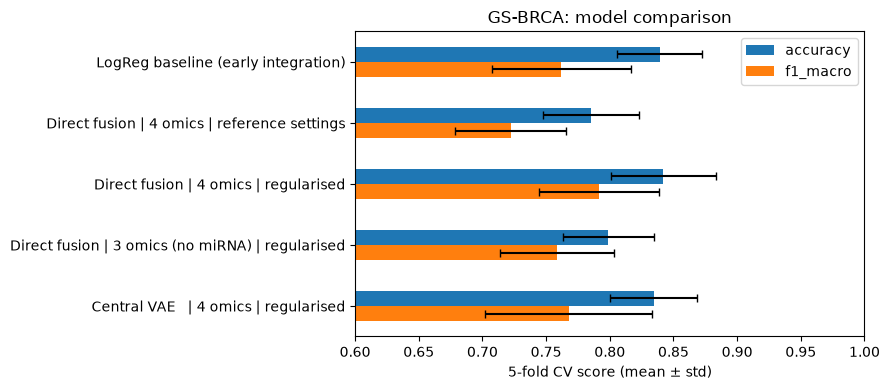

In [6]:
comparison = summary_table([baseline] + runs)
comparison.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"))
display(comparison)

means = pd.DataFrame({r["name"]: r["folds"][["accuracy", "f1_macro"]].mean() for r in [baseline] + runs}).T
stds = pd.DataFrame({r["name"]: r["folds"][["accuracy", "f1_macro"]].std() for r in [baseline] + runs}).T
ax = means.plot.barh(xerr=stds, figsize=(9, 4), capsize=3)
ax.set_xlim(0.6, 1.0); ax.set_xlabel("5-fold CV score (mean ± std)"); ax.invert_yaxis()
ax.set_title("GS-BRCA: model comparison")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "model_comparison.png"), dpi=200); plt.show()

## 5. Best model: save and analyse

The best model is chosen by mean macro-F1 over the 5 test folds. Its 5 fold models (weights + fitted preprocessing),
the metrics, the out-of-fold predictions and the latent vectors are saved to `results/brca/`.

In [7]:
best = max(runs, key=lambda r: r["folds"]["f1_macro"].mean())
print("Best model:", best["name"])

summary, per_class = save_run(best, RESULTS_DIR)
display(best["folds"].round(4))
print("\nMean ± std over 5 folds")
display(summary.round(4))
print("\nPer-class metrics (pooled out-of-fold predictions)")
display(per_class.round(3))

Best model: Direct fusion | 4 omics | regularised


,fold,accuracy,precision,recall,f1_macro,roc_auc,nmi,ari,best_epoch
0,1,0.8444,0.7887,0.8384,0.8012,0.9703,0.6537,0.6330,4
1,2,0.7761,0.7096,0.8047,0.7407,0.9419,0.5928,0.5074,4
2,3,0.8358,0.7420,0.7559,0.7450,0.9267,0.6272,0.6538,19
3,4,0.8731,0.8442,0.8218,0.8302,0.9691,0.6849,0.7185,35
4,5,0.8806,0.8547,0.8309,0.8421,0.9802,0.6820,0.7142,9



Mean ± std over 5 folds


,mean,std
accuracy,0.8420,0.0414
precision,0.7879,0.0630
recall,0.8103,0.0329
f1_macro,0.7918,0.0471
roc_auc,0.9576,0.0224
nmi,0.6481,0.0388
ari,0.6454,0.0857



Per-class metrics (pooled out-of-fold predictions)


,precision,recall,f1-score,support
0,0.904,0.856,0.879,353.000
1,0.711,0.762,0.736,42.000
2,0.721,0.765,0.743,132.000
3,0.550,0.710,0.620,31.000
4,0.964,0.956,0.960,113.000
accuracy,0.842,0.842,0.842,0.842
macro avg,0.770,0.810,0.787,671.000
weighted avg,0.850,0.842,0.845,671.000


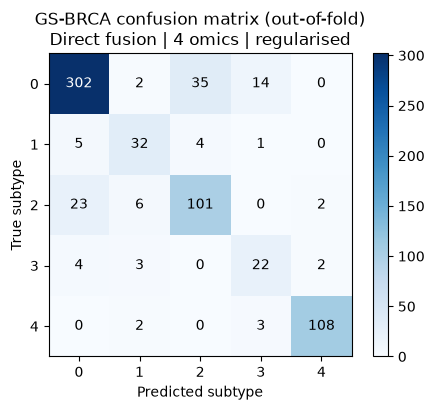

In [8]:
y_pred = best["oof_proba"].argmax(1)
cm = confusion_matrix(y, y_pred)

fig, ax = plt.subplots(figsize=(5, 4.2))
im = ax.imshow(cm, cmap="Blues")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.set_xlabel("Predicted subtype"); ax.set_ylabel("True subtype")
ax.set_title(f"GS-BRCA confusion matrix (out-of-fold)\n{best['name']}")
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=200); plt.show()

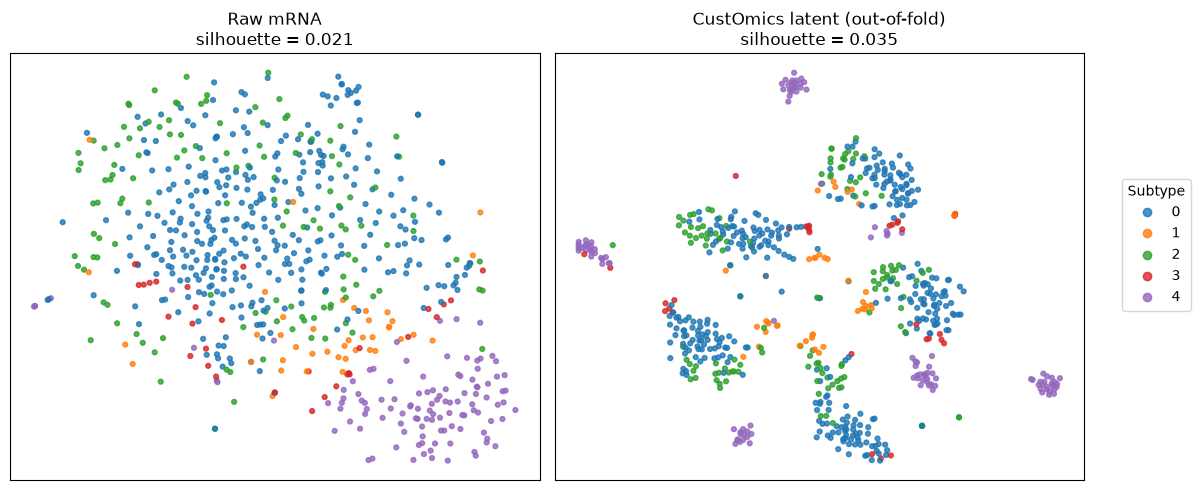

In [9]:
# Latent space: every patient is embedded by the fold model that never saw it during training
raw_mrna = StandardScaler().fit_transform(X_all["mRNA"])
embeddings = {"Raw mRNA": raw_mrna, "CustOmics latent (out-of-fold)": best["oof_latent"]}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, emb) in zip(axes, embeddings.items()):
    xy = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(emb)
    sc = ax.scatter(xy[:, 0], xy[:, 1], c=y, cmap="tab10", vmin=0, vmax=9, s=12, alpha=0.8)
    ax.set_title(f"{title}\nsilhouette = {silhouette_score(emb, y):.3f}")
    ax.set_xticks([]); ax.set_yticks([])
fig.legend(*sc.legend_elements(), title="Subtype", loc="center right")
plt.tight_layout(rect=(0, 0, 0.92, 1))
plt.savefig(os.path.join(RESULTS_DIR, "latent_tsne.png"), dpi=200); plt.show()